## 1. Load Dataset
Read the original TSV file

In [1]:
import pandas as pd

data_dir = "../data/raw/all_data_en/"
prefix = "crisis_consolidated_humanitarian_filtered_lang_en_"

train_df = pd.read_csv(data_dir + prefix + "train.tsv", sep="\t")
dev_df = pd.read_csv(data_dir + prefix + "dev.tsv", sep="\t")
test_df = pd.read_csv(data_dir + prefix + "test.tsv", sep="\t")

print("Train:", train_df.shape)
print("Dev:", dev_df.shape)
print("Test:", test_df.shape)

train_df.head()

Train: (61164, 7)
Dev: (8935, 7)
Test: (17356, 7)


,id,event,source,text,lang,lang_conf,class_label
0,18582,disaster_events,drd-figureeight-multimedia,Approximately 100km long firebreaks have been ...,en,1.0,infrastructure_and_utilities_damage
1,592616302138658817,2015_nepal_earthquake,crisisnlp-volunteers,God bless you... https://t.co/AnEy1ydkkz,en,NaN,not_humanitarian
2,503643491143282688,2014_california_earthquake,crisisnlp-cf,"RT @perreaux: Cracked wine casks, damaged hist...",en,NaN,infrastructure_and_utilities_damage
3,323833109051228160,2013_boston_bombings-ontopic,crisislext6,I'm really just excited for new undies and pin...,en,1.0,not_humanitarian
4,508333923886067712,2014_pakistan_floods,crisisnlp-cf,"Rescue effort expands in India, Pakistan as fl...",en,1.0,injured_or_dead_people


## 2. Dataset Overview
Inspect the columns, data types, and a few rows. Add a split indicator for combined exploratory summaries.

In [2]:
df = pd.concat([
    train_df.assign(split="train"),
    dev_df.assign(split="dev"),
    test_df.assign(split="test")
], ignore_index=True)

print("Combined shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
display(df.sample(min(5, len(df)), random_state=42))

Combined shape: (87455, 8)
Columns: ['id', 'event', 'source', 'text', 'lang', 'lang_conf', 'class_label', 'split']

Data types:
id               int64
event           object
source          object
text            object
lang            object
lang_conf      float64
class_label     object
split           object
dtype: object


,id,event,source,text,lang,lang_conf,class_label,split
3221,324750102533132289,2013_west-texas_explosion,crisislext26,"RT @andr3wgriggs: My prayers go out to Waco, T...",en,1.0,sympathy_and_support,train
63282,295496058585350145,2013_queensland_floods-ontopic,crisislext6,I'm so impressed with @qpsmediaunit - their di...,en,1.0,not_humanitarian,dev
4685,326503692574539776,2013_west_texas,crisislext6,I am the key holder at my job now. #trust #pim...,en,1.0,not_humanitarian,train
16261,541676861936631808,2014_philippines_typhoon-hagupit,crisisnlp-volunteers,#TyphoonHagupit thankfully less destructive th...,en,NaN,not_humanitarian,train
24097,323928866496315392,2013_boston_bombings-ontopic,crisislext6,"I love that dirty water, Boston you're my home...",en,1.0,not_humanitarian,train


## 3. Humanitarian Category Analysis
Count examples per label, visualize class imbalance, and compare the label proportions in each split.

,count,percent
class_label,,
not_humanitarian,51584,58.98
donation_and_volunteering,7388,8.45
requests_or_needs,6901,7.89
sympathy_and_support,5104,5.84
infrastructure_and_utilities_damage,5050,5.77
affected_individual,3510,4.01
caution_and_advice,2990,3.42
injured_or_dead_people,2773,3.17
response_efforts,1114,1.27


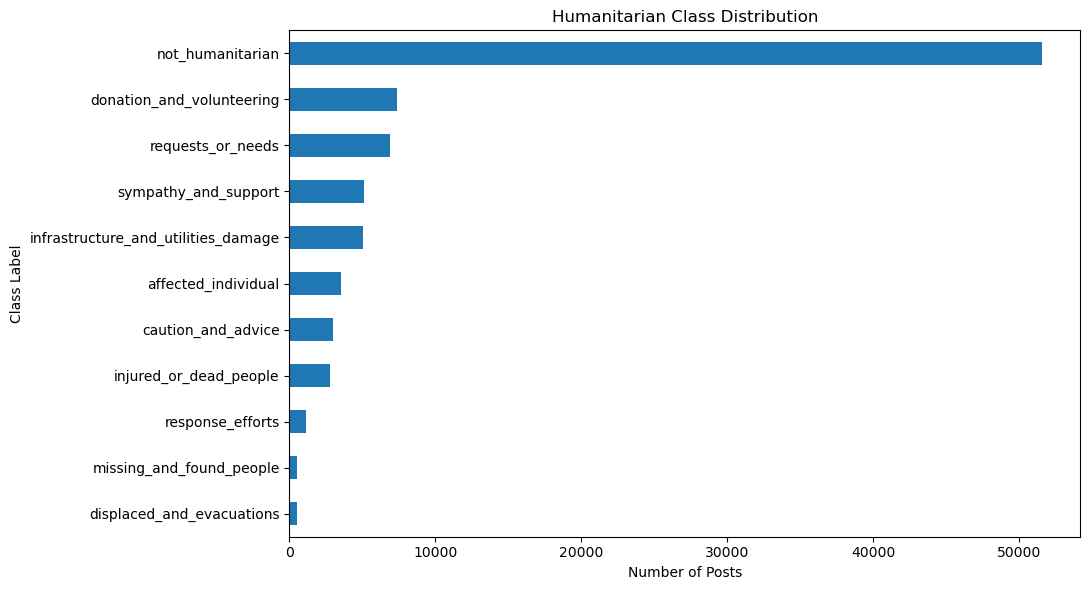

In [3]:
from matplotlib import pyplot as plt

label_counts = df["class_label"].value_counts(dropna=False)
label_summary = pd.DataFrame({
    "count": label_counts,
    "percent": (label_counts / len(df) * 100).round(2)
})
display(label_summary)

ax = label_counts.sort_values().plot.barh(figsize=(11, 6))
ax.set(title="Humanitarian Class Distribution", xlabel="Number of Posts", ylabel="Class Label")
plt.tight_layout()
plt.show()

In [4]:
split_label = pd.crosstab(df["class_label"], df["split"])
display(split_label)
display(pd.crosstab(df["split"], df["class_label"], normalize="index").mul(100).round(1))

split,dev,test,train
class_label,,,
affected_individual,366,692,2452
caution_and_advice,307,583,2100
displaced_and_evacuations,53,99,358
donation_and_volunteering,761,1452,5175
infrastructure_and_utilities_damage,509,1002,3539
injured_or_dead_people,270,561,1942
missing_and_found_people,55,103,373
not_humanitarian,5260,10253,36071
requests_or_needs,702,1370,4829


class_label,affected_individual,caution_and_advice,displaced_and_evacuations,donation_and_volunteering,infrastructure_and_utilities_damage,injured_or_dead_people,missing_and_found_people,not_humanitarian,requests_or_needs,response_efforts,sympathy_and_support
split,,,,,,,,,,,
dev,4.1,3.4,0.6,8.5,5.7,3.0,0.6,58.9,7.9,1.3,6.0
test,4.0,3.4,0.6,8.4,5.8,3.2,0.6,59.1,7.9,1.3,5.9
train,4.0,3.4,0.6,8.5,5.8,3.2,0.6,59.0,7.9,1.3,5.8


## 4. Crisis Event Analysis
Inspect the number of unique event identifiers and how posts are distributed. Check whether event names refer to individual crises or generic groupings before defining cross-crisis tests.

Unique non-null events: 60


,posts
event,
disaster_events,12551
2015_nepal_earthquake,9653
2014_philippines_typhoon-hagupit,5766
2013_oklahoma_tornado-ontopic,4988
2013_west_texas,4624
2013_alberta_floods-ontopic,4562
2013_queensland_floods-ontopic,4390
2013_boston_bombings-ontopic,4176
2012_sandy_hurricane-ontopic,3679


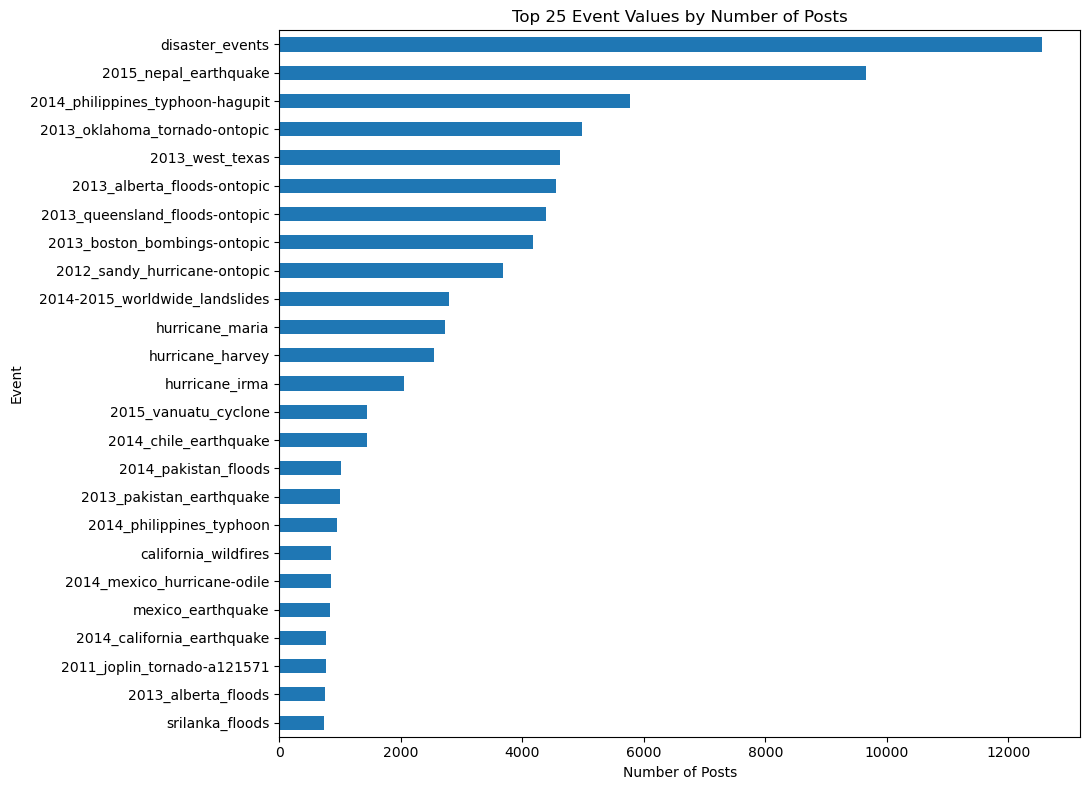

In [5]:
event_counts = df["event"].value_counts(dropna=False)
print("Unique non-null events:", df["event"].nunique())
display(event_counts.to_frame("posts"))

ax = event_counts.head(25).sort_values().plot.barh(figsize=(11, 8))
ax.set(title="Top 25 Event Values by Number of Posts", xlabel="Number of Posts", ylabel="Event")
plt.tight_layout()
plt.show()

### 4.1 Humanitarian Labels Across Events
This table identifies which events have enough examples from each class to support meaningful comparisons.

class_label,affected_individual,caution_and_advice,displaced_and_evacuations,donation_and_volunteering,infrastructure_and_utilities_damage,injured_or_dead_people,missing_and_found_people,not_humanitarian,requests_or_needs,response_efforts,sympathy_and_support
event,,,,,,,,,,,
2011_joplin_tornado-a121571,0,410,0,189,0,125,43,0,0,0,0
2011_joplin_tornado-a131709,0,0,0,0,0,0,0,43,0,0,0
2012_colorado_wildfires,132,43,0,74,64,0,0,10,0,0,157
2012_costa-rica_earthquake,16,65,0,0,11,0,0,20,0,0,23
2012_guatemala_earthquake,62,9,0,3,2,0,0,2,0,0,18
2012_italy_earthquakes,52,5,0,0,5,0,0,2,0,0,13
2012_philipinnes_floods,113,69,0,229,44,0,0,11,0,0,70
2012_philippines_typhoon-pablo,105,141,0,98,32,0,0,9,0,0,139
2012_sandy_hurricane-ontopic,0,0,0,0,0,0,0,3679,0,0,0


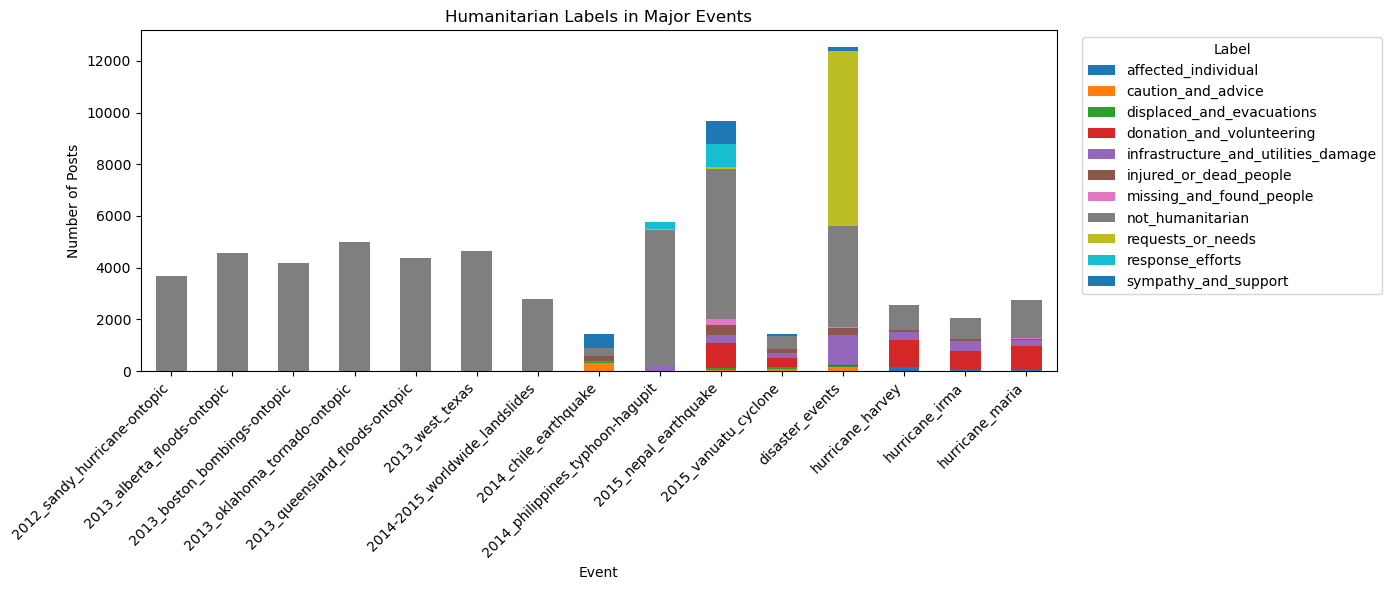

In [6]:
event_label_counts = pd.crosstab(df["event"], df["class_label"])
display(event_label_counts)

# show the largest events first for a more manageable overview.
top_events = event_counts.head(15).index
ax = event_label_counts.loc[event_label_counts.index.intersection(top_events)].plot(
    kind="bar", stacked=True, figsize=(14, 6)
)
ax.set(title="Humanitarian Labels in Major Events", xlabel="Event", ylabel="Number of Posts")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Label", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 4.2 Event Overlap Across Original Splits
Check which events appear in more than one split.

In [7]:
events_by_split = {
    "train": set(train_df["event"].dropna()),
    "dev": set(dev_df["event"].dropna()),
    "test": set(test_df["event"].dropna())
}
for left, right in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    overlap = events_by_split[left] & events_by_split[right]
    print(f"{left} / {right}: {len(overlap)} overlapping event values")
    print("Examples:", sorted(map(str, overlap))[:10])

train / dev: 60 overlapping event values
Examples: ['2011_joplin_tornado-a121571', '2011_joplin_tornado-a131709', '2012_colorado_wildfires', '2012_costa-rica_earthquake', '2012_guatemala_earthquake', '2012_italy_earthquakes', '2012_philipinnes_floods', '2012_philippines_typhoon-pablo', '2012_sandy_hurricane-ontopic', '2012_us_sandy-hurricane-a143145']
train / test: 60 overlapping event values
Examples: ['2011_joplin_tornado-a121571', '2011_joplin_tornado-a131709', '2012_colorado_wildfires', '2012_costa-rica_earthquake', '2012_guatemala_earthquake', '2012_italy_earthquakes', '2012_philipinnes_floods', '2012_philippines_typhoon-pablo', '2012_sandy_hurricane-ontopic', '2012_us_sandy-hurricane-a143145']
dev / test: 60 overlapping event values
Examples: ['2011_joplin_tornado-a121571', '2011_joplin_tornado-a131709', '2012_colorado_wildfires', '2012_costa-rica_earthquake', '2012_guatemala_earthquake', '2012_italy_earthquakes', '2012_philipinnes_floods', '2012_philippines_typhoon-pablo', '2012

## 5. Data Quality Checks
Check missing values and repeated text.

In [8]:
missing = df.isna().sum().to_frame("missing_count")
missing["missing_percent"] = (missing["missing_count"] / len(df) * 100).round(2)
display(missing)

print("Exact duplicate text rows:", df.duplicated(subset=["text"]).sum())
print("Duplicate non-null IDs:", df.loc[df["id"].notna(), "id"].duplicated().sum())

for left_name, left, right_name, right in [
    ("train", train_df, "dev", dev_df),
    ("train", train_df, "test", test_df),
    ("dev", dev_df, "test", test_df)
]:
    left_texts = set(left["text"].dropna().astype(str))
    right_texts = set(right["text"].dropna().astype(str))
    print(f"Text overlap {left_name}/{right_name}: {len(left_texts & right_texts)}")

,missing_count,missing_percent
id,0,0.00
event,0,0.00
source,0,0.00
text,0,0.00
lang,0,0.00
lang_conf,37401,42.77
class_label,0,0.00
split,0,0.00


Exact duplicate text rows: 0
Duplicate non-null IDs: 1
Text overlap train/dev: 0
Text overlap train/test: 0
Text overlap dev/test: 0


## 6. Sample Post Inspection

In [9]:
for label, group in df.groupby("class_label", dropna=False):
    print(f"\n{'=' * 60}\nLABEL: {label} ({len(group):,} posts)")
    for _, row in group.sample(n=min(3, len(group)), random_state=42).iterrows():
        print(f"Event: {row['event']} | Text: {str(row['text'])[:350]}")


LABEL: affected_individual (3,510 posts)
Event: 2013_glasgow_helicopter-crash | Text: RT @p_mcpartlin: Esperanza, the band playing at #Clutha tonight say on Facebook they are all safe but don't know about others in pub http:/…
Event: 2013_colorado_floods | Text: Rain is still pouring down in #Colorado. 500 unaccounted for by the #floods, hopefully rescue efforts are successful.
Event: 2013_bohol_earthquake | Text: Tragic pictures of Philippines quake survivor woes: http://t.co/9yK23rDrNr @irinnews

LABEL: caution_and_advice (2,990 posts)
Event: disaster_events | Text: BSCA Cyclone Komen to bring very heavy rains in Odisha: The deep depression over northeastern Bay of Bengal to... http://t.co/5uSOk608kk
Event: 2013_bohol_earthquake | Text: RT @sunstaronline: Mayor Rama: Classes in all levels in private &amp; public schools in #Cebu City will resume on Nov. 4, Monday. #walangpasok …
Event: disaster_events | Text: #Rohingya #Muslims Bangladesh braces for tropical Cyclone Komen: There are

## EDA Progress

### Completed
Initial EDA using CrisisBench `all_data_en` (87,455 posts).

- Dataset: Loaded train/dev/test sets.
- Labels: Analyzed 11 categories; `not_humanitarian` makes up ~59% of posts.
- Events: Analyzed 60 crisis event identifiers and label distributions.
- Event overlap: All 60 events appear in train/dev/test, so new splits are needed for cross-crisis testing.
- Data quality: Checked missing values, duplicates, and sample posts. Found one duplicate ID but no duplicate texts.

### Remaining

**1. Event Aliases**
- Identify and group event names that refer to the same crisis (e.g., `2013_alberta_floods` and `2013_alberta_floods-ontopic`).
- Decide how to handle generic events like `disaster_events`.

**2. Duplicate ID**
- Examine the duplicate ID and decide whether it needs to be removed.

**3. Cross-Crisis Splits**
- Create train/dev/test splits with no overlapping crisis events.
- Check label distributions and save splits for both models.
- Keep original splits for standard evaluation.

**4. Finalize EDA**
- Summarize findings and decisions.
- Confirm labels, preprocessing steps, and evaluation metrics.